
# Fixed Income Risk Dashboard
## Task 1 — Daily Rates Desk Risk Report

### Objective
Build an end-of-day risk report for a simulated government
bond trading desk.

The report converts market data and trading positions into
portfolio valuation, interest-rate sensitivities, and
historical risk estimates.

### Processing Workflow

1. **Market Data Ingestion**
   - Load daily zero-coupon yield curves.
   - Extract 11 curve tenors (3M to 30Y).
   - Load reported desk P&L.

2. **Position Reconstruction**
   - Process the trade blotter.
   - Apply ticket amendments.
   - Calculate outstanding positions as of the report date.

3. **Bond Valuation**
   - Generate future coupon and principal cash flows.
   - Interpolate zero rates across the yield curve.
   - Discount future cash flows to present value.

4. **Interest Rate Risk**
   - Calculate Key-Rate DV01 for each bond.
   - Aggregate sensitivities across the portfolio.
   - Validate analytical DV01 against ±1bp repricing.

5. **Historical Simulation VaR**
   - Collect 500 historical daily yield-curve changes.
   - Estimate portfolio P&L under each scenario.
   - Calculate 1-day 99% VaR using the fifth-worst outcome.

6. **Daily Reporting**
   - Generate desk risk metrics and position details.
   - Export the results to a formatted Excel workbook.

### Technology Stack
Python | NumPy | pandas | Matplotlib | C# | ClosedXML | Excel

### Scope
Simulated fixed-income desk, end-of-day reporting.
Not a live trading or order execution system.


Morning report for the close of 2024-12-31 (17 live positions)
   bond face_m years        value    dv01
 GOV_25    +40  0.62  +39,974,109  +2,459
 GOV_26    +30  1.45  +29,896,197  +4,259
 GOV_27   +100  2.87  +97,185,111 +26,765
GOV_27B     +4  2.37   +4,026,126    +911
 GOV_28   +260  3.37 +257,699,331 +81,732
 GOV_29    +90  4.13  +88,945,441 +33,847
GOV_29B     +8  4.62   +7,977,917  +3,352
 GOV_30   +100  5.13  +99,565,821 +45,932
 GOV_31   -170  6.62 -169,764,908 -97,905
 GOV_32    -80  7.38  -72,560,539 -48,100
 GOV_33    -60  8.13  -56,990,895 -39,950
 GOV_34    -50  9.13  -50,066,822 -37,698
 GOV_37    +40 12.88  +38,359,992 +38,587
 GOV_42    -30 17.63  -25,854,958 -33,489
 GOV_44    -15 19.14  -15,016,165 -19,338
 GOV_52    +35 27.64  +27,100,579 +46,805
 GOV_53    +25 28.64  +23,859,303 +39,065
Net value USD +324,335,641;  net DV01 USD +47,234;  gross DV01 (sum of |position DV01|) USD 600,193
Key-rate DV01 ladder (USD per 1bp fall at each vertex):
  3M: +117  6M: +2,065  1

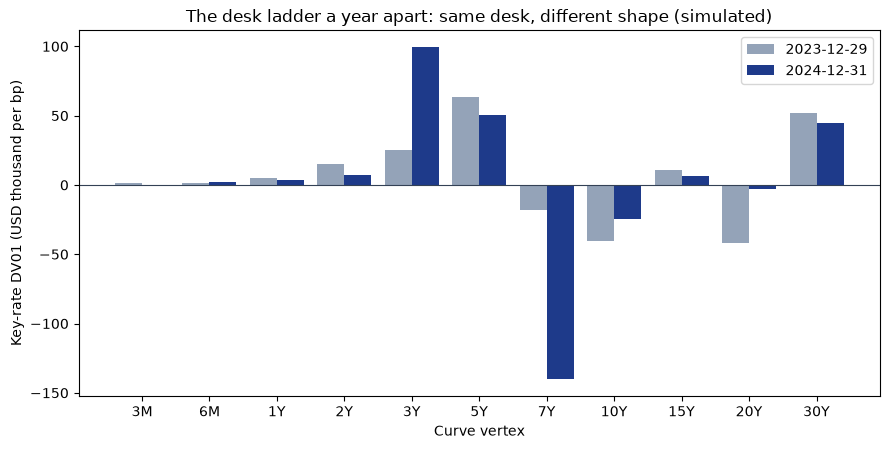

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# == Setup (done for you) ==
df = pd.read_csv(
    r'C:\Users\franklinpeng\Desktop\RDA Risk test\DataSource\rates_desk_feed.csv',
    parse_dates=['date'],
    index_col='date'
)
DATES = df.index                                   # business days 2020-12-31 .. 2024-12-31
LAB = [c[2:] for c in df.columns if c.startswith('Z_')]          # '3M', '6M', ..., '30Y'
TEN = np.array([0.25, 0.5, 1, 2, 3, 5, 7, 10, 15, 20, 30])       # years of the Z_ columns: the curve's VERTICES
Z = df[['Z_' + x for x in LAB]].to_numpy()         # the curve FEED as received: zero yields, %, continuously compounded
PNL = df['PNL_REPORTED'].to_numpy()                # the P&L system's daily desk P&L, USD (NaN before 2023-01-03)
REP = np.where(DATES >= '2023-01-03')[0]           # report mornings: every day with a reported P&L
BONDS = {   # bond: (coupon % a year, paid twice a year, maturity date)
    'GOV_23': (0.875, '2023-09-30'), 'GOV_24': (1.500, '2024-05-15'), 'GOV_25': (2.750, '2025-08-15'),
    'GOV_26': (4.125, '2026-06-15'), 'GOV_27': (3.250, '2027-11-15'), 'GOV_27B': (4.500, '2027-05-15'),
    'GOV_28': (4.000, '2028-05-15'), 'GOV_29': (3.750, '2029-02-15'), 'GOV_29B': (4.000, '2029-08-15'),
    'GOV_30': (4.000, '2030-02-15'), 'GOV_31': (4.125, '2031-08-15'), 'GOV_32': (2.875, '2032-05-15'),
    'GOV_33': (3.500, '2033-02-15'), 'GOV_34': (4.250, '2034-02-15'), 'GOV_37': (4.000, '2037-11-15'),
    'GOV_42': (3.250, '2042-08-15'), 'GOV_44': (4.375, '2044-02-15'), 'GOV_52': (3.000, '2052-08-15'),
    'GOV_53': (4.125, '2053-08-15'),
}
IDS = list(BONDS)
BLOTTER = [   # the risk system's trade blotter: (ticket, booked, traded, bond, face USD m: + bought / - sold)
    ('T001', '2022-12-30', '2022-12-30', 'GOV_23', 70), ('T002', '2022-12-30', '2022-12-30', 'GOV_24', 60),
    ('T003', '2022-12-30', '2022-12-30', 'GOV_25', 80), ('T004', '2022-12-30', '2022-12-30', 'GOV_27', 150),
    ('T005', '2022-12-30', '2022-12-30', 'GOV_29', 90), ('T006', '2022-12-30', '2022-12-30', 'GOV_32', -120),
    ('T007', '2022-12-30', '2022-12-30', 'GOV_33', -60), ('T008', '2022-12-30', '2022-12-30', 'GOV_37', 40),
    ('T009', '2022-12-30', '2022-12-30', 'GOV_42', -50), ('T010', '2022-12-30', '2022-12-30', 'GOV_52', 35),
    ('T011', '2023-02-14', '2023-02-14', 'GOV_26', 50), ('T012', '2023-04-20', '2023-04-20', 'GOV_32', 40),
    ('T013', '2023-06-07', '2023-06-07', 'GOV_30', 70), ('T014', '2023-08-23', '2023-08-23', 'GOV_44', -30),
    ('T015', '2023-10-11', '2023-10-11', 'GOV_27', -50), ('T016', '2023-11-29', '2023-11-29', 'GOV_53', 25),
    ('T017', '2024-01-17', '2024-01-17', 'GOV_25', -40), ('T018', '2024-02-21', '2024-02-21', 'GOV_30', 30),
    ('T019', '2024-04-10', '2024-04-10', 'GOV_34', 50), ('T019', '2024-04-16', '2024-04-10', 'GOV_34', -50),
    ('T020', '2024-05-22', '2024-05-22', 'GOV_42', 20),
    ('T021', '2024-06-12', '2024-06-12', 'GOV_27B', 40), ('T021', '2024-06-26', '2024-06-12', 'GOV_27B', 4),
    ('T022', '2024-08-07', '2024-08-07', 'GOV_44', 15),
    ('T026', '2024-08-21', '2024-08-21', 'GOV_28', 260), ('T027', '2024-08-21', '2024-08-21', 'GOV_31', -170),
    ('T023', '2024-09-12', '2024-09-09', 'GOV_29B', 8),
    ('T025', '2024-12-04', '2024-12-04', 'GOV_26', -20),
]   # a ticket that appears twice was AMENDED: its later row replaces the earlier one from that booked date
VAR_DAYS, VAR_K = 500, 5    # 1-day 99% HS VaR: the 5th worst of the last 500 daily curve moves (1% of 500)


def cash_flows(bond):
    """Done for you: the bond's payment dates after the data starts (every 6 months back from maturity, unadjusted)
    and its payments per 100 face: coupon / 2 on each date, + 100 at maturity."""
    cpn, mat = BONDS[bond]
    mat = pd.Timestamp(mat)
    dates = pd.DatetimeIndex([mat - pd.DateOffset(months=6 * k) for k in range(80)][::-1])
    dates = dates[dates > DATES[0]]
    cf = np.full(len(dates), cpn / 2)
    cf[-1] += 100.0
    return dates, cf


def interp_weights(tau):
    """Done for you: weights W (shape tau.shape + (11,)) with W @ curve = the zero rate at each tau, linear between
    vertices and flat beyond the first and last. Each row has at most two non-zero weights, summing to 1."""
    tc = np.clip(tau, TEN[0], TEN[-1])
    j = np.clip(np.searchsorted(TEN, tc, side='right') - 1, 0, len(TEN) - 2)
    a = (tc - TEN[j]) / (TEN[j + 1] - TEN[j])
    W = np.zeros(np.shape(tau) + (len(TEN),))
    np.put_along_axis(W, j[..., None], (1 - a)[..., None], axis=-1)
    W2 = np.zeros_like(W)
    np.put_along_axis(W2, (j + 1)[..., None], a[..., None], axis=-1)
    return W + W2


def book_on(day, blotter=BLOTTER):
    """TODO: The desk's position in each bond at the close of `day`, as an array of USD m face in IDS order.
    Keep the blotter rows booked on or before `day`, keep the LAST row of each ticket (an amendment replaces
    the original), then add up the face by bond."""
    tickets = pd.DataFrame(blotter, columns=['ticket', 'booked', 'traded', 'bond', 'face_m'])
    tickets['booked'] = pd.to_datetime(tickets['booked'])
    tickets = tickets.loc[tickets['booked'] <= pd.Timestamp(day)]
    latest = tickets.drop_duplicates('ticket', keep='last')
    return (latest.groupby('bond')['face_m']
            .sum()
            .reindex(IDS, fill_value=0)
            .to_numpy())


def price_and_ladder(bond, curve, day):
    """TODO: Value per 100 face of `bond` on `day` off a zero curve (11 rates in %, continuously compounded), and its
    key-rate DV01 ladder per 100 face (11 numbers: the gain if that vertex alone FALLS 1bp).
    Only payments after `day` count. tau = (payment date - day).days / 365; z = interp_weights(tau) @ curve;
    value = sum cf exp(-z / 100 x tau); ladder = (cf x tau x exp(-z / 100 x tau)) @ interp_weights(tau) x 1e-4."""
    """
    Calculate:
      1. Bond present value per 100 face.
      2. Key-rate DV01 ladder across 11 curve vertices.

    A positive DV01 represents a gain from a 1bp rate fall.
    """
    dates, cf = cash_flows(bond)
    tau = np.asarray((dates - pd.Timestamp(day)).days / 365.0)
    keep = tau > 0
    tau, cf = tau[keep], cf[keep]
    if len(tau) == 0:
        return 0.0, np.zeros(len(TEN))
    W = interp_weights(tau)
    z = W @ curve
    dfac = np.exp(-z / 100.0 * tau)
    value = cf @ dfac
    ladder = (cf * tau * dfac) @ W * 1e-4
    return float(value), ladder


def hs_var(ladder, moves):
    """TODO: 1-day 99% historical-simulation VaR in USD. Each row of `moves` is one past daily curve move (11 numbers,
    bp); its P&L on the book is -moves @ ladder (a ladder is the gain when rates FALL). VaR = minus the VAR_K-th
    worst P&L."""
  
    # Revalue using linear key-rate sensitivities
    pnl = -moves @ ladder

    # Fifth worst historical daily P&L
    kth_worst = np.partition(pnl, VAR_K - 1)[VAR_K - 1]

    return -float(kth_worst)


# ---------------------------------------------------------------------------
_day = DATES[-1]
checks = [('book_on', lambda: book_on(_day)),
          ('price_and_ladder', lambda: price_and_ladder('GOV_34', Z[-1], _day)),
          ('hs_var', lambda: hs_var(np.ones(11), np.diff(Z[-501:], axis=0) * 100))]
todo = next((name for name, f in checks if f() is None), None)
if todo:
    print(f"Fill in the TODOs above, then run again. Next: {todo}()")
else:
    def report(i):
        """The morning report for the close of DATES[i]: positions, values and ladders in USD, and the VaR."""
        day, curve = DATES[i], Z[i]
        face = book_on(day)
        rows, L = [], np.zeros(11)
        for bond, q in zip(IDS, face):
            if q == 0:
                continue
            v, lad = price_and_ladder(bond, curve, day)
            if v == 0:
                continue          # matured: still on the blotter, no payments left
            L += q * 1e4 * lad    # face USD m x 1e6 / 100 = q x 1e4 USD per unit of price per 100
            rows.append((bond, q, (pd.Timestamp(BONDS[bond][1]) - day).days / 365, q * 1e4 * v, q * 1e4 * lad.sum()))
        moves = np.diff(Z[i - VAR_DAYS:i + 1], axis=0) * 100      # the last 500 daily moves, bp
        return pd.DataFrame(rows, columns=['bond', 'face_m', 'years', 'value', 'dv01']), L, hs_var(L, moves), moves

    i = len(DATES) - 1
    pos, L, var, moves = report(i)
    print(f"Morning report for the close of {DATES[i].date()} ({len(pos)} live positions)")
    print(pos.to_string(index=False, formatters={'face_m': '{:+,.0f}'.format, 'years': '{:.2f}'.format,
                                                 'value': '{:+,.0f}'.format, 'dv01': '{:+,.0f}'.format}))
    print(f"Net value USD {pos.value.sum():+,.0f};  net DV01 USD {L.sum():+,.0f};  "
          f"gross DV01 (sum of |position DV01|) USD {pos.dv01.abs().sum():,.0f}")
    print("Key-rate DV01 ladder (USD per 1bp fall at each vertex):")
    print('  ' + '  '.join(f"{a}: {b:+,.0f}" for a, b in zip(LAB, L)))

    # the ladder by formula vs by bumping each vertex 1bp up and down and repricing
    face = book_on(DATES[i])
    def book_value(curve):
        return sum(q * 1e4 * price_and_ladder(b, curve, DATES[i])[0] for b, q in zip(IDS, face) if q)
    bump = np.array([(book_value(Z[i] - 0.01 * e) - book_value(Z[i] + 0.01 * e)) / 2 for e in np.eye(11)])
    print(f"Ladder by formula vs by +-1bp bumps, largest relative gap within 1e-6: "
          f"{bool(np.max(np.abs(bump - L)) / np.abs(L).max() < 1e-6)}")

    par = moves.mean(axis=1, keepdims=True) * np.ones((1, 11))     # each day's move, flattened to its average
    print(f"\n1-day 99% HS VaR (5th worst of {len(moves)} curve moves): USD {var:,.0f}")
    print(f"Same moves flattened to parallel (DV01 alone sees only these): USD {hs_var(L, par):,.0f}")
    print(f"Worst single move in the window: {pd.Series(-moves @ L, index=DATES[i - VAR_DAYS + 1:i + 1]).idxmin().date()}"
          f", P&L USD {(-moves @ L).min():,.0f}")

    j = DATES.searchsorted(pd.Timestamp('2023-12-29'))
    pos0, L0, var0, _ = report(j)
    _, Ly, vary, _ = report(i - 1)
    print(f"\n{'':<12}{'net DV01':>12}{'VaR 99%':>12}")
    for lbl, a, b in ((str(DATES[j].date()), L0.sum(), var0), (str(DATES[i - 1].date()), Ly.sum(), vary),
                      (str(DATES[i].date()), L.sum(), var)):
        print(f"{lbl:<12}{a:>+12,.0f}{b:>12,.0f}")
    print("Task 2 walks from one report to the next and says what moved each number.")

    fig, ax = plt.subplots(figsize=(9, 4.6))
    x = np.arange(11)
    ax.bar(x - 0.2, L0 / 1e3, 0.4, color='#94a3b8', label=str(DATES[j].date()))
    ax.bar(x + 0.2, L / 1e3, 0.4, color='#1e3a8a', label=str(DATES[i].date()))
    ax.axhline(0, color='#334155', lw=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels(LAB)
    ax.set_xlabel('Curve vertex')
    ax.set_ylabel('Key-rate DV01 (USD thousand per bp)')
    ax.set_title('The desk ladder a year apart: same desk, different shape (simulated)')
    ax.legend()
    plt.tight_layout()
    plt.show()



## Core Risk Metrics & Calculation Methodology

This section explains the four primary financial risk metrics used in the Fixed Income Risk Dashboard: **Bond Present Value, Key-Rate DV01, Net DV01, and Historical Simulation VaR**.

The objective is to translate daily market data and bond positions into measurable portfolio valuation and interest-rate risk.

---

### 1. Bond Present Value (PV)

**Definition**

The present value of a bond is the sum of its future coupon and principal payments, discounted using the continuously compounded zero-coupon yield curve.

$$
PV = \sum_{i=1}^{N} CF_i e^{-z(\tau_i)\tau_i}
$$

Where:

- $CF_i$: Coupon or principal cash flow at payment date $i$.
- $\tau_i$: Years remaining until payment, calculated using ACT/365.
- $z(\tau_i)$: Continuously compounded zero rate at maturity $\tau_i$, expressed as a decimal.
- $e^{-z(\tau_i)\tau_i}$: Discount factor.

**Implementation**

1. Generate semiannual coupon and principal cash flows.
2. Calculate the remaining maturity of each future payment.
3. Interpolate the zero-coupon yield curve across 11 maturity vertices.
4. Calculate discount factors.
5. Sum the discounted cash flows to obtain the bond price per $100 face value.

**Business Interpretation**

- Higher yields generally reduce the present value of fixed-rate bonds.
- Longer-dated cash flows are generally more sensitive to interest-rate changes.
- Portfolio market value is calculated by scaling each bond price by its outstanding face amount.

**Python Function:** `price_and_ladder()`

---

### 2. Key-Rate DV01 (KRDV01)

**Definition**

Key-Rate DV01 measures the approximate change in a bond's dollar value when one specific vertex of the yield curve decreases by one basis point (0.01 percentage points), holding other vertices constant.

$$
KRDV01_k =
10^{-4}
\sum_{i=1}^{N}
CF_i \tau_i e^{-z(\tau_i)\tau_i} W_{ik}
$$

Where:

- $k$: One of the 11 yield-curve vertices.
- $W_{ik}$: Linear interpolation weight assigned to vertex $k$ for cash flow $i$.
- $10^{-4}$: One basis point expressed as a decimal rate change.

**Implementation**

1. Calculate the discounted value of each future cash flow.
2. Compute sensitivity to the zero rate at each payment maturity.
3. Allocate sensitivities across curve vertices using interpolation weights.
4. Aggregate bond-level sensitivities using position sizes.

**Business Interpretation**

Key-Rate DV01 identifies where a trading book is exposed along the yield curve.

A portfolio may have a small net DV01 while retaining large offsetting exposures at different maturities.

For example, a positive 3Y DV01 and negative 7Y DV01 create exposure to changes in the shape of the yield curve.

**Python Functions:** `interp_weights()`, `price_and_ladder()`, `report()`

---

### 3. Net DV01 

**Definition**

Net DV01 is the sum of the portfolio's Key-Rate DV01 exposures across all curve vertices.

$$
Net\ DV01 = \sum_{k=1}^{11} KRDV01_k
$$

For a small parallel shift in the yield curve:

$$
\Delta PV \approx -Net\ DV01 \times \Delta y_{bp}
$$

Where:

- $\Delta y_{bp}$: Parallel yield change measured in basis points.
- Positive Net DV01: Portfolio generally gains when yields fall.
- Negative Net DV01: Portfolio generally gains when yields rise.

**Example — December 31, 2024**

| Risk Metric | Value |
|---|---:|
| Net DV01 | +$47,234 / bp |
| Gross Position DV01 | $600,193 / bp |
| 3Y Key-Rate DV01 | +$99,575 / bp |
| 7Y Key-Rate DV01 | -$140,251 / bp |

**Business Interpretation**

The difference between Net DV01 and Gross Position DV01 indicates substantial offsetting long and short interest-rate exposures.

A low Net DV01 does not necessarily imply low portfolio risk because non-parallel yield-curve movements can generate significant gains or losses.

**Python Function:** `report()`

---

### 4. Historical Simulation VaR (HS VaR)

**Definition**

Historical Simulation Value at Risk estimates a portfolio loss threshold using historical market movements applied to the current risk exposure.

This project calculates **1-day 99% VaR using 500 historical daily yield-curve moves**.

For each historical scenario $s$:

$$
P\&L_s \approx
-\sum_{k=1}^{11}
KRDV01_k \times \Delta y_{s,k}
$$

Where:

- $KRDV01_k$: Current portfolio sensitivity at vertex $k$, in USD per bp.
- $\Delta y_{s,k}$: Historical daily change at vertex $k$, measured in basis points.
- $P\&L_s$: Estimated portfolio profit or loss under scenario $s$.

The scenario results are sorted from worst to best.

With 500 observations and a 99% confidence level:

$$
500 \times (1-0.99) = 5
$$

Therefore:

$$
VaR_{99\%} = -P\&L_{(5)}
$$

Here, $P\&L_{(5)}$ represents the fifth-worst historical scenario result.

**Implementation**

1. Extract the latest 500 historical daily curve changes.
2. Convert yield changes from percentage points to basis points.
3. Apply each historical shock to today's Key-Rate DV01 ladder.
4. Calculate 500 estimated portfolio P&L outcomes.
5. Sort outcomes and select the fifth-worst result.


**Business Interpretation**

The estimated 1-day 99% VaR is approximately $939K.

Under the empirical historical distribution and the model's assumptions, approximately 1% of comparable daily scenarios exceed this loss threshold.

VaR is not the maximum possible loss and does not guarantee that losses remain below the estimated threshold.

**Python Function:** `hs_var()`

---

### 5. Model Validation & Limitations

**Validation**

The analytical Key-Rate DV01 ladder is compared against the central-difference result from repricing each curve vertex after a +1bp and -1bp shock.

$$
KRDV01_k^{bump}
\approx
\frac{PV(z_k-1bp)-PV(z_k+1bp)}{2}
$$

The implementation checks that the maximum relative difference is below $10^{-6}$.

**Model Assumptions**

- Government bond portfolio with fixed semiannual coupons.
- Continuously compounded zero-coupon yield curves.
- Linear interpolation between the 11 curve vertices.
- Flat extrapolation beyond the first and last vertices.
- ACT/365 year fractions.
- First-order DV01 approximation for Historical VaR.
- No full bond repricing for each historical VaR scenario.
- No explicit credit spread, liquidity, funding, or transaction-cost model.

**Reporting Scope**

This dashboard is built using a simulated fixed-income trading book and historical market data for educational and portfolio demonstration purposes.

It is an end-of-day risk reporting application, not a live trading, execution, or production risk management system.


In [15]:
import json
import base64
import io
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

output_dir = Path(
    r"C:\Users\franklinpeng\Desktop\RDA Risk test\Excel_Template_Output"
)
output_dir.mkdir(parents=True, exist_ok=True)

i = len(DATES) - 1
j = DATES.searchsorted(pd.Timestamp("2023-12-29"))

pos, L, var99, moves = report(i)
_, L_prev, var_prev, _ = report(i - 1)
_, L_year, _, _ = report(j)

scenario_pnl = -moves @ L
scenario_dates = DATES[i - len(moves) + 1:i + 1]

def encode_chart(fig):
    buffer = io.BytesIO()
    fig.savefig(buffer, format="png", dpi=145,
                bbox_inches="tight", facecolor="white")
    plt.close(fig)
    return base64.b64encode(buffer.getvalue()).decode("ascii")

# Chart 1: historical vs current key-rate exposures
fig, ax = plt.subplots(figsize=(9.4, 3.15))
x = np.arange(len(LAB))

ax.bar(x - 0.19, L_year / 1000, width=0.38,
       color="#A5B4C5", label="2023-12-29")
ax.bar(x + 0.19, L / 1000, width=0.38,
       color=np.where(L >= 0, "#078C86", "#CD5260"),
       label="2024-12-31")

ax.axhline(0, color="#334155", linewidth=0.9)
ax.set_xticks(x, LAB)
ax.set_ylabel("USD thousands / bp")
ax.legend(frameon=False, loc="upper right", ncol=2)
ax.grid(axis="y", alpha=0.14)
ax.set_axisbelow(True)

curve_image = encode_chart(fig)

# Chart 2: five largest historical losses
worst = np.argsort(scenario_pnl)[:5]
losses = -scenario_pnl[worst] / 1e6
labels = [scenario_dates[k].strftime("%Y-%m-%d") for k in worst]

fig, ax = plt.subplots(figsize=(7.8, 3.1))
y = np.arange(len(worst))

ax.barh(y, losses, color="#CD5260", height=0.55)
ax.set_yticks(y, labels)
ax.invert_yaxis()
ax.set_xlim(0, max(losses) * 1.28)
ax.set_xlabel("Loss magnitude (USD millions)")
ax.grid(axis="x", alpha=0.14)
ax.set_axisbelow(True)

for k, amount in enumerate(losses):
    ax.text(amount + max(losses) * 0.018, k,
            f"${amount:.2f}M", va="center", fontsize=9)

loss_image = encode_chart(fig)

payload = {
    "asOf": DATES[i].strftime("%Y-%m-%d"),
    "previousAsOf": DATES[i - 1].strftime("%Y-%m-%d"),
    "reportedPnl": float(PNL[i]) if np.isfinite(PNL[i]) else None,
    "previousVar": float(var_prev),
    "previousNetDv01": float(L_prev.sum()),
    "var99": float(var99),
    "curveImage": curve_image,
    "lossImage": loss_image,
    "positions": [
        {
            "bond": r.bond,
            "face_m": float(r.face_m),
            "years": float(r.years),
            "value": float(r.value),
            "dv01": float(r.dv01)
        }
        for r in pos.itertuples(index=False)
    ],
    "ladder": [
        {
            "tenor": tenor,
            "dv01": float(current),
            "yearAgo": float(previous)
        }
        for tenor, current, previous in zip(LAB, L, L_year)
    ],
    "scenarios": [
        {
            "date": date.strftime("%Y-%m-%d"),
            "pnl": float(pnl)
        }
        for date, pnl in zip(scenario_dates, scenario_pnl)
    ]
}

snapshot = output_dir / "task1_snapshot.json"
snapshot.write_text(json.dumps(payload), encoding="utf-8")

print("Snapshot ready:", snapshot)
print("Positions:", len(pos))
print("Scenarios:", len(scenario_pnl))
print("VaR:", f"${var99:,.0f}")


Snapshot ready: C:\Users\franklinpeng\Desktop\RDA Risk test\Excel_Template_Output\task1_snapshot.json
Positions: 17
Scenarios: 500
VaR: $939,306


In [16]:
import subprocess

result = subprocess.run(
    [
        "dotnet",
        "run",
        "--file",
        r"C:\Users\franklinpeng\Desktop\RDA Risk test\DeskRiskExcel.cs"
    ],
    capture_output=True,
    text=True,
    encoding="utf-8",
    errors="replace"
)

print("Exit Code:", result.returncode)

print("\n=== STDOUT ===")
print(result.stdout)

print("\n=== STDERR ===")
print(result.stderr)


Exit Code: 0

=== STDOUT ===
SUCCESS
Excel: C:\Users\franklinpeng\Desktop\RDA Risk test\Excel_Template_Output\RatesDesk_DailyRisk_V2_2024-12-31.xlsx
Net DV01: +47,234
Gross DV01: 600,193
Historical VaR: $939,306
Positions: 17
Scenarios: 500


=== STDERR ===

